In [104]:
#Lab 1

In [105]:
import csv
import os

from datetime import datetime, timedelta

import numpy as np
import matplotlib.pyplot as plt

In [106]:
def generate_time_series(
    n_points=1000,
    variance_mode="const",
    trend_mode="none",
    seasonality_mode="none",
    base_value=100,
    seed=None
):
    """
    Генерирует синтетический временной ряд.

    Parameters
    ----------
    n_points : int
        Количество точек временного ряда.

    variance_mode : str
        Режим дисперсии:
        'const', 'grow', 'decay', 'random'.

    trend_mode : str
        Режим тренда:
        'none',
        'fast_up',
        'slow_up',
        'fast_down',
        'slow_down',
        'random'.

    seasonality_mode : str
        Режим сезонности:
        'none', 'one', 'two', 'random'.

    base_value : float
        Базовый уровень временного ряда.

    seed : int | None
        Начальное значение генератора случайных чисел.

    Returns
    -------
    timestamps : list
        Временные метки.

    values : np.ndarray
        Значения временного ряда.

    metadata : dict
        Использованные параметры генерации.
    """

    if n_points <= 0:
        raise ValueError("Количество точек должно быть положительным")

    rng = np.random.default_rng(seed)

    # -------------------------------------------
    # Возможные режимы
    # -------------------------------------------

    variance_modes = ["const", "grow", "decay"]

    trend_modes = [
        "none",
        "fast_up",
        "slow_up",
        "fast_down",
        "slow_down"
    ]

    seasonality_modes = ["none", "one", "two"]

    # -------------------------------------------
    # Обработка режима random
    # -------------------------------------------

    if variance_mode == "random":
        variance_mode = rng.choice(variance_modes)

    if trend_mode == "random":
        trend_mode = rng.choice(trend_modes)

    if seasonality_mode == "random":
        seasonality_mode = rng.choice(seasonality_modes)

    # -------------------------------------------
    # Проверка параметров
    # -------------------------------------------

    if variance_mode not in variance_modes:
        raise ValueError(
            f"Неизвестный variance_mode: {variance_mode}"
        )

    if trend_mode not in trend_modes:
        raise ValueError(
            f"Неизвестный trend_mode: {trend_mode}"
        )

    if seasonality_mode not in seasonality_modes:
        raise ValueError(
            f"Неизвестный seasonality_mode: {seasonality_mode}"
        )

    # -------------------------------------------
    # Временная шкала
    # Начало: 00:00 текущего дня
    # Шаг: 5 минут
    # -------------------------------------------

    start_time = datetime.now().replace(
        hour=0,
        minute=0,
        second=0,
        microsecond=0
    )

    timestamps = [
        start_time + timedelta(minutes=5 * i)
        for i in range(n_points)
    ]

    # Индекс времени:
    # 0, 1, 2, ..., n_points - 1
    t = np.arange(n_points)

    # -------------------------------------------
    # Дисперсия случайного шума
    # -------------------------------------------

    if variance_mode == "const":
        variance = np.full(n_points, 4.0)

    elif variance_mode == "grow":
        variance = np.linspace(
            1.0,
            9.0,
            n_points
        )

    elif variance_mode == "decay":
        variance = np.linspace(
            9.0,
            1.0,
            n_points
        )

    # Для нормального шума параметр scale —
    # это стандартное отклонение,
    # поэтому берём корень из дисперсии.
    noise = rng.normal(
        loc=0,
        scale=np.sqrt(variance),
        size=n_points
    )

    # -------------------------------------------
    # Тренд
    # -------------------------------------------

    if trend_mode == "none":
        trend = np.zeros(n_points)

    elif trend_mode == "slow_up":
        trend = np.linspace(
            0,
            10,
            n_points
        )

    elif trend_mode == "fast_up":
        trend = np.linspace(
            0,
            40,
            n_points
        )

    elif trend_mode == "slow_down":
        trend = np.linspace(
            0,
            -10,
            n_points
        )

    elif trend_mode == "fast_down":
        trend = np.linspace(
            0,
            -40,
            n_points
        )

    # -------------------------------------------
    # Сезонность
    # -------------------------------------------

    if seasonality_mode == "none":
        seasonality = np.zeros(n_points)

    elif seasonality_mode == "one":

        # Один период = 1 час.
        # При шаге 5 минут:
        # 60 / 5 = 12 точек.
        period_1 = 12

        seasonality = (
            5
            * np.sin(
                2 * np.pi * t / period_1
            )
        )

    elif seasonality_mode == "two":

        # Первая сезонность:
        # 1 час = 12 точек.
        period_1 = 12

        # Вторая сезонность:
        # 6 часов = 72 точки.
        period_2 = 72

        seasonality = (
            5
            * np.sin(
                2 * np.pi * t / period_1
            )
            +
            2.5
            * np.sin(
                2 * np.pi * t / period_2
            )
        )

    # -------------------------------------------
    # Итоговый временной ряд
    # -------------------------------------------

    values = (
        base_value
        + trend
        + seasonality
        + noise
    )

    metadata = {
        "n_points": n_points,
        "interval_minutes": 5,
        "variance_mode": variance_mode,
        "trend_mode": trend_mode,
        "seasonality_mode": seasonality_mode,
        "base_value": base_value,
        "seed": seed
    }

    return timestamps, values, metadata

In [107]:
def save_to_csv(
    timestamps,
    values,
    folder="."
):
    """
    Сохраняет временной ряд в CSV-файл.
    """

    os.makedirs(
        folder,
        exist_ok=True
    )

    current_time = datetime.now()

    base_name = current_time.strftime(
        "ts_%Y%m%d_%H%M%S"
    )

    filename = f"{base_name}.csv"

    filepath = os.path.join(
        folder,
        filename
    )

    # Если файл уже существует,
    # добавляем суффикс.
    counter = 1

    while os.path.exists(filepath):

        filename = (
            f"{base_name}_{counter}.csv"
        )

        filepath = os.path.join(
            folder,
            filename
        )

        counter += 1

    with open(
        filepath,
        "w",
        newline="",
        encoding="utf-8"
    ) as file:

        writer = csv.writer(file)

        writer.writerow([
            "timestamp",
            "value"
        ])

        for timestamp, value in zip(
            timestamps,
            values
        ):
            writer.writerow([
                timestamp.strftime(
                    "%Y-%m-%d %H:%M:%S"
                ),
                f"{value:.6f}"
            ])

    print(
        f"CSV сохранён: {filepath}"
    )

    return filepath

In [108]:
def plot_time_series(
    timestamps,
    values,
    metadata,
    save_path=None
):
    """
    Строит график временного ряда
    и при необходимости сохраняет PNG.
    """

    plt.figure(
        figsize=(14, 6)
    )

    plt.plot(
        timestamps,
        values
    )

    title = (
        "Синтетический временной ряд\n"
        f"variance={metadata['variance_mode']}, "
        f"trend={metadata['trend_mode']}, "
        f"seasonality={metadata['seasonality_mode']}"
    )

    plt.title(title)

    plt.xlabel("Время")
    plt.ylabel("Значение")

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    if save_path is not None:

        directory = os.path.dirname(
            save_path
        )

        if directory:
            os.makedirs(
                directory,
                exist_ok=True
            )

        plt.savefig(
            save_path,
            dpi=150,
            bbox_inches="tight"
        )

        print(
            f"График сохранён: {save_path}"
        )

    plt.show()

{'n_points': 1000, 'interval_minutes': 5, 'variance_mode': 'const', 'trend_mode': 'fast_down', 'seasonality_mode': 'one', 'base_value': 100, 'seed': 42}


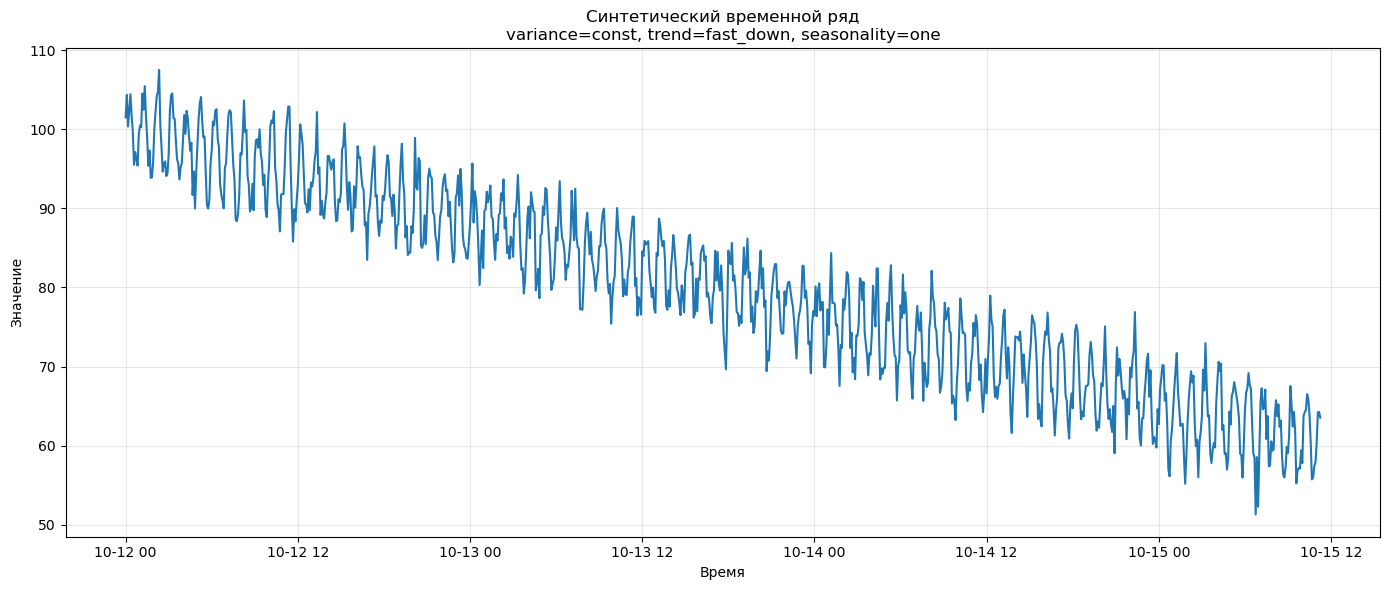

In [109]:
timestamps, values, metadata = generate_time_series(
    n_points=1000,
    variance_mode="random",
    trend_mode="random",
    seasonality_mode="random",
    seed=42
)

print(metadata)

plot_time_series(
    timestamps,
    values,
    metadata
)

In [110]:
csv_path = save_to_csv(
    timestamps,
    values
)

CSV сохранён: ./ts_20261012_111730.csv


График сохранён: images/lab_image_1.png


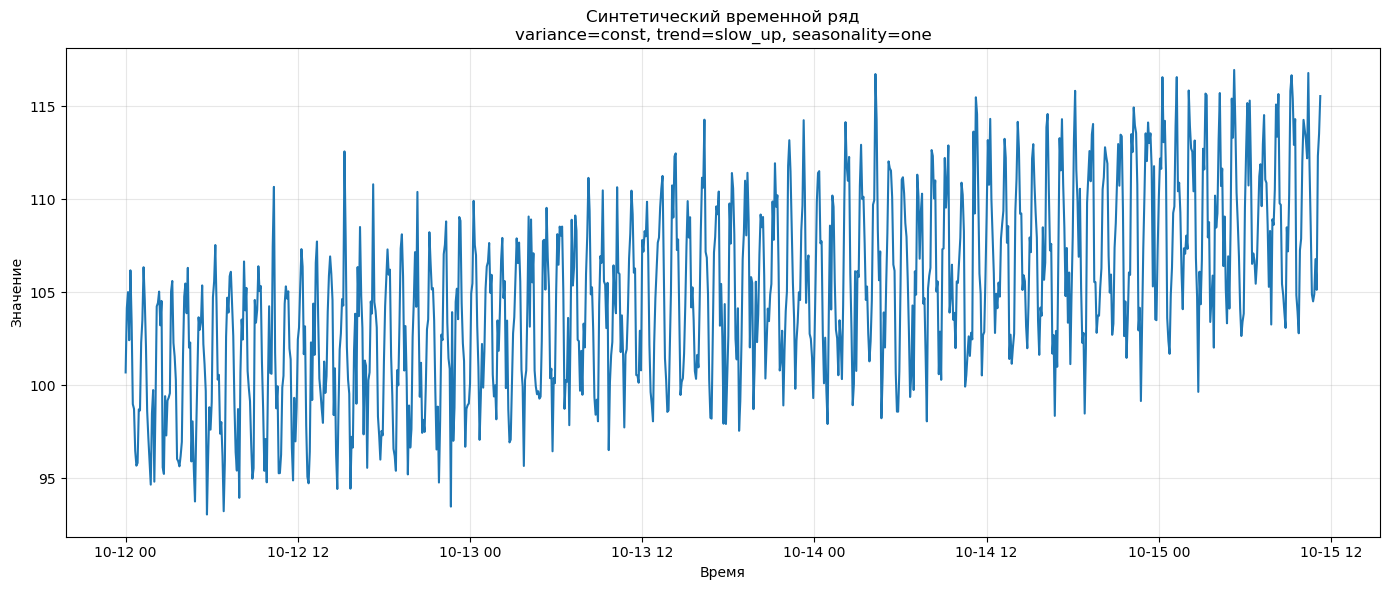

In [111]:
#постоянная дисперсия + медленный рост + одна сезонность
timestamps_1, values_1, metadata_1 = generate_time_series(
    n_points=1000,
    variance_mode="const",
    trend_mode="slow_up",
    seasonality_mode="one",
    seed=1
)

plot_time_series(
    timestamps_1,
    values_1,
    metadata_1,
    save_path="images/lab_image_1.png"
)

График сохранён: images/lab_image_2.png


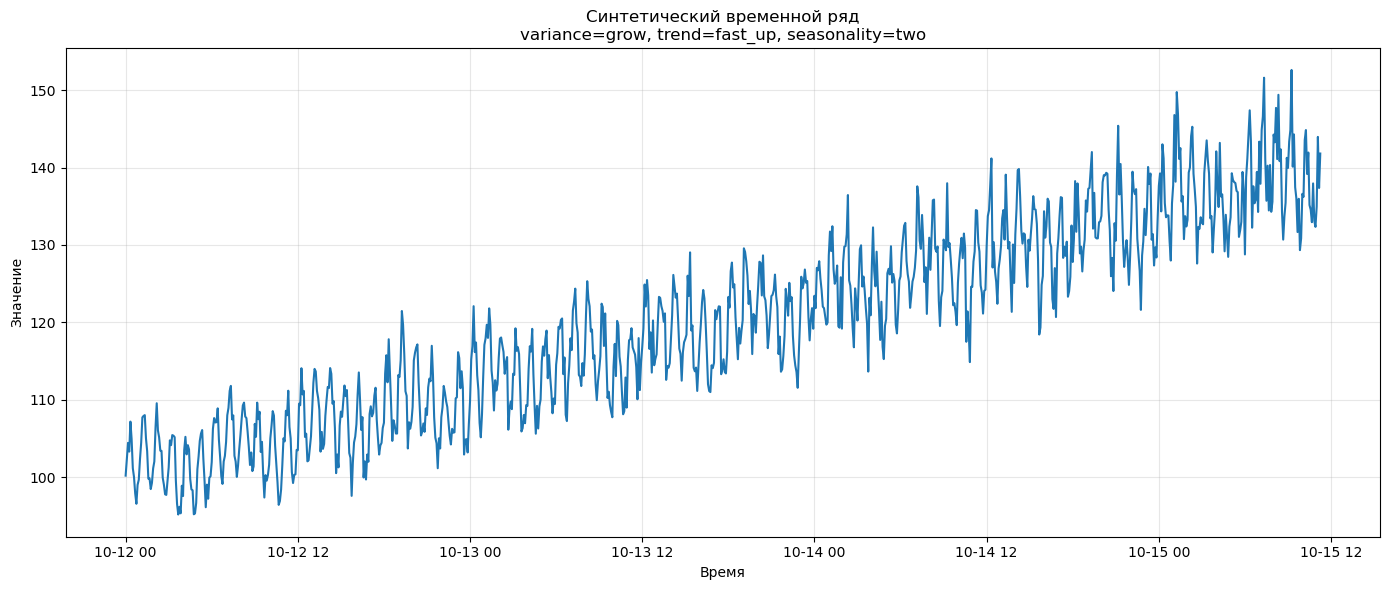

In [112]:
#Растущая дисперсия + быстрый рост + две сезонности
timestamps_2, values_2, metadata_2 = generate_time_series(
    n_points=1000,
    variance_mode="grow",
    trend_mode="fast_up",
    seasonality_mode="two",
    seed=2
)

plot_time_series(
    timestamps_2,
    values_2,
    metadata_2,
    save_path="images/lab_image_2.png"
)

График сохранён: images/lab_image_3.png


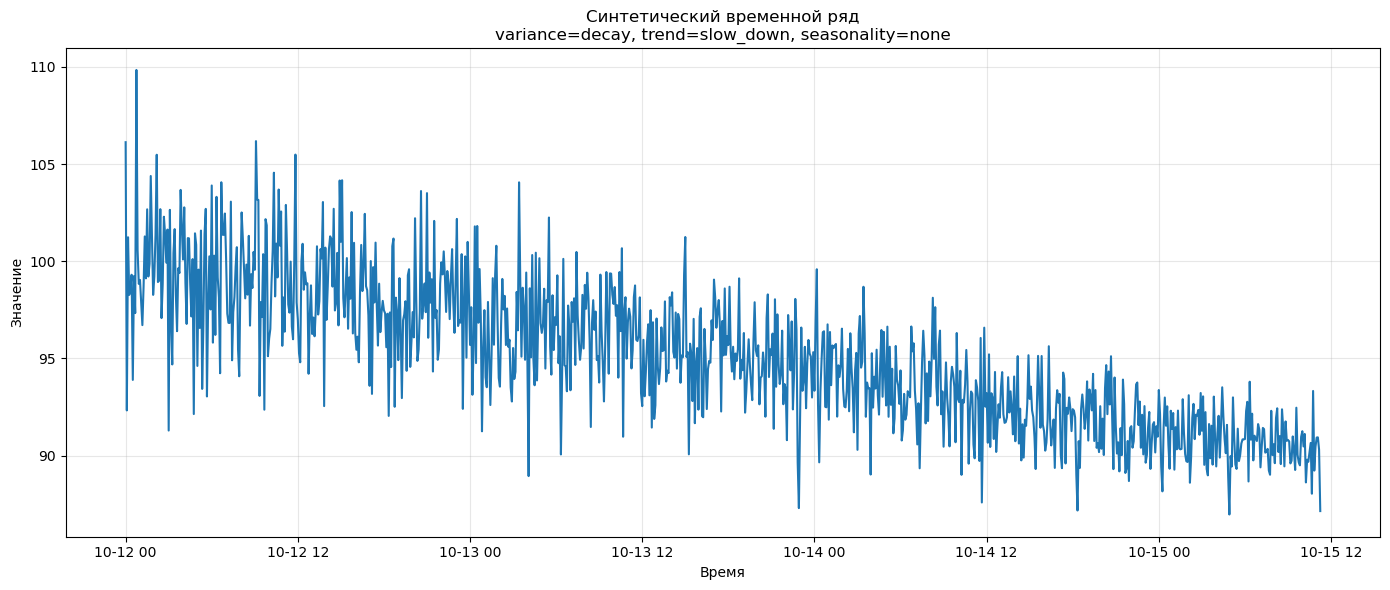

In [113]:
# Убывающая дисперсия + медленное падение + отсутствие сезонности.
timestamps_3, values_3, metadata_3 = generate_time_series(
    n_points=1000,
    variance_mode="decay",
    trend_mode="slow_down",
    seasonality_mode="none",
    seed=3
)

plot_time_series(
    timestamps_3,
    values_3,
    metadata_3,
    save_path="images/lab_image_3.png"
)